<a href="https://colab.research.google.com/github/tlgus9989-art/bigdataHackathon/blob/main/%EB%B9%85%EB%8D%B0%EC%9D%B4%ED%84%B0_%ED%94%84%EB%A1%9C%EA%B7%B8%EB%9E%98%EB%B0%8D_%ED%95%B4%EC%BB%A4%ED%86%A4_%EC%84%B1%EB%8A%A5_63_33.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 단일 CNN · 기울기와 약한 노이즈를 이용한 쓰레기 분류
김시현 · 5695460

Kaggle 원본 이미지를 URL로 받아 단일 8층 CNN을 무작위 초기화부터 학습한다. 기준은 제출 #14의 모델 구조와 원본 검증 기준이다. 사진의 방향이 조금 달라지고 픽셀에 약한 잡음이 생겨도 재질 단서를 활용할 수 있는지를 실험한다. 유리의 색을 보존하고 물체 전체가 잘리지 않도록 증강 강도를 제한했다.
Colab GPU에서 1~8-2절을 실행하면 제출 ZIP이 생성된다. 9절은 새 사진을 직접 분류하는 선택 실습이다.


## 1. URL 데이터 다운로드 및 실행 환경

In [ ]:
from urllib.request import urlretrieve
from pathlib import Path
from tempfile import mkdtemp
from zipfile import ZipFile
import hashlib
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

DATA_URL = "https://www.kaggle.com/api/v1/datasets/download/mostafaabla/garbage-classification"
ZIP_PATH = Path("/content/archive.zip")
print("Kaggle 데이터 다운로드 중...")
urlretrieve(DATA_URL, ZIP_PATH)
print("다운로드 완료")
work = Path(mkdtemp(prefix="trash_", dir="/content"))
with ZipFile(ZIP_PATH) as archive:
    archive.extractall(work)

root = next(p.parent for p in work.rglob("paper") if (p.parent / "plastic").is_dir())
source = datasets.ImageFolder(root)
assert len(source.classes) == 12, source.classes
seed = 12345
torch.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, root, len(source), source.classes)
print("torch:", torch.__version__)

import torchvision
import platform
runtime_info = {
    "python": platform.python_version(), "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__), "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "cudnn_benchmark": torch.backends.cudnn.benchmark,
    "cudnn_deterministic": torch.backends.cudnn.deterministic,
    "deterministic_algorithms": torch.are_deterministic_algorithms_enabled()
}
print("이번 실행 환경:", runtime_info)


Kaggle 데이터 다운로드 중...
다운로드 완료
cuda /content/trash_slk3js52/garbage_classification 15515 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
torch: 2.14.1+cu130
이번 실행 환경: {'python': '3.13.16', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'cuda': '13.0', 'cudnn': 92800, 'gpu': 'Tesla T4', 'cudnn_benchmark': False, 'cudnn_deterministic': False, 'deterministic_algorithms': False}


## 2. 기존과 동일한 중복 제거·분할
파일 바이트 중복 제거 후 클래스별 약 70:15:15 분할, seed=12345. 기존 시험셋의 결과를 이미 본 상태이므로 새 결과를 완전히 새로운 독립 검증이라고 주장하지 않습니다. 이번 설정 선택에는 검증셋만 사용하고 서버 평가는 최종 확인으로 남겨둡니다.

In [ ]:
from collections import defaultdict

by_hash = defaultdict(list)
for idx, (path, label) in enumerate(source.samples):
    digest = hashlib.sha256(Path(path).read_bytes()).digest()
    by_hash[digest].append((idx, label))

by_class = defaultdict(list)
for group in by_hash.values():
    if len({label for _, label in group}) == 1:
        idx, label = group[0]
        by_class[label].append(idx)

rng = torch.Generator().manual_seed(seed)
train_ids, val_ids, test_ids = [], [], []
print("클래스 | 학습 | 검증 | 시험")
for label, name in enumerate(source.classes):
    ids = by_class[label]
    ids = [ids[i] for i in torch.randperm(len(ids), generator=rng).tolist()]
    n_val = n_test = int(len(ids) * 0.15)
    n_train = len(ids) - n_val - n_test
    train_ids.extend(ids[:n_train])
    val_ids.extend(ids[n_train:n_train + n_val])
    test_ids.extend(ids[n_train + n_val:])
    print(name, n_train, n_val, n_test)
print("중복·라벨 충돌로 제외:", len(source) - len(train_ids) - len(val_ids) - len(test_ids))

클래스 | 학습 | 검증 | 시험
battery 663 141 141
biological 691 147 147
brown-glass 425 91 91
cardboard 625 133 133
clothes 3728 798 798
green-glass 430 92 92
metal 538 115 115
paper 736 157 157
plastic 605 129 129
shoes 1385 296 296
trash 489 104 104
white-glass 542 115 115
중복·라벨 충돌로 제외: 22


## 3. 학습 사진 변형과 검증 조건
#14의 전처리 셀을 바탕으로 반사 패딩 후 회전, 약한 이동, 텐서 노이즈를 적용한다. 입력 128×128, 클래스 균형 샘플링, 약한 색상 조정과 좌우 반전을 유지한다. 노이즈 표준편차는 정규화 전 픽셀 범위 [0, 1] 기준이다. 학습 원본 파일은 그대로 두고 배치를 읽을 때 변형한다.


In [ ]:
from datetime import datetime
import json
from torch.utils.data import WeightedRandomSampler

IMG_SIZE = 128
BATCH_SIZE = 32
run_dir = Path("/content") / ("trash_noise_angle_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
run_dir.mkdir()
plain_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])
from torchvision.transforms import functional as TF, InterpolationMode

def add_noise(x):
    sigma = torch.empty(()).uniform_(0.01, 0.04)
    return (x + torch.randn_like(x) * sigma).clamp(0, 1)

aug_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.Pad(24, padding_mode="reflect"),
    transforms.RandomApply([transforms.RandomAffine(
        degrees=15, translate=(0.03, 0.03),
        interpolation=InterpolationMode.BILINEAR)], p=0.65),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.08),
    transforms.ToTensor(),
    transforms.RandomApply([add_noise], p=0.35),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

class FixedPerturbation(torch.utils.data.Dataset):
    """각 검증 사진에 고정된 기울기와 잡음을 적용해 회차 간 비교가 가능하게 한다."""
    def __init__(self, source, indices):
        self.source = source
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, pos):
        idx = self.indices[pos]
        image, label = self.source[idx]
        image = TF.resize(image, [IMG_SIZE, IMG_SIZE])
        image = TF.pad(image, 24, padding_mode="reflect")
        angle = 12 if idx % 2 else -12
        image = TF.rotate(image, angle, interpolation=InterpolationMode.BILINEAR)
        x = TF.to_tensor(TF.center_crop(image, IMG_SIZE))
        rng = torch.Generator().manual_seed(seed + idx)
        noise = torch.randn(x.shape, generator=rng) * 0.025
        return TF.normalize((x + noise).clamp(0, 1), [0.5]*3, [0.5]*3), label

perturbed_val_loader = DataLoader(FixedPerturbation(source, val_ids), batch_size=BATCH_SIZE)
plain_data = datasets.ImageFolder(root, transform=plain_tf)
aug_data = datasets.ImageFolder(root, transform=aug_tf)
train_eval_loader = DataLoader(Subset(plain_data, train_ids), batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(Subset(plain_data, val_ids), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(Subset(plain_data, test_ids), batch_size=BATCH_SIZE, shuffle=False)
train_labels = torch.tensor([source.samples[i][1] for i in train_ids])
class_counts = torch.bincount(train_labels, minlength=len(source.classes))
sample_weights = 1.0 / class_counts[train_labels].double()
manifest = {name: [{"path": str(Path(source.samples[i][0]).relative_to(root)),
                    "label": source.samples[i][1]} for i in ids]
            for name, ids in {"train": train_ids, "val": val_ids, "test": test_ids}.items()}
(run_dir / "splits.json").write_text(json.dumps(
    {"classes": source.classes, "seed": seed, "splits": manifest}, indent=2), encoding="utf-8")
(run_dir / "runtime_info.json").write_text(json.dumps(runtime_info, indent=2), encoding="utf-8")
print("저장 위치:", run_dir)


저장 위치: /content/trash_noise_angle_20261125_064917_559063


## 4. 개선 CNN 구조
완전연결층에 집중되었던 용량을 특징 추출에 배분합니다. 각 단계에서 합성곱 두 번 후 해상도를 줄이며 마지막은 4×4 평균 풀링으로 공간 정보를 일부 남깁니다. BN 앞 합성곱 bias는 사용하지 않습니다. 마지막 출력은 Softmax 이전 logits입니다.

In [ ]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class ImprovedCNN(nn.Module):
    def __init__(self, n_classes=12, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),      # 128 -> 64
            conv_block(32, 64),     # 64 -> 32
            conv_block(64, 128),    # 32 -> 16
            conv_block(128, 192),   # 16 -> 8
        )
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(192 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

probe = ImprovedCNN(len(source.classes))
print("학습 파라미터:", sum(p.numel() for p in probe.parameters()))
probe.eval()
with torch.no_grad():
    print("출력 크기:", probe(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).shape)
del probe


학습 파라미터: 1236076
출력 크기: torch.Size([1, 12])


## 5. 평가 함수
전체 CE·정확도와 클래스 평균 CE·재현율을 함께 계산합니다. 모델 선택과 스케줄러는 클래스 평균 CE를 사용합니다. 클래스 평균 재현율은 각 클래스에 같은 가중치를 주므로 12종을 같은 수로 평가하는 서버와 비교하기 좋습니다. 학습 성능 측정도 증강 없는 eval 모드로 통일합니다.

In [ ]:
def measure(model, loader):
    model.eval()
    n = len(source.classes)
    confusion = torch.zeros(n, n, dtype=torch.long)
    loss_by_class = torch.zeros(n, dtype=torch.float64)
    with torch.no_grad():
        for x, y in loader:
            logits = model(x.to(device))
            losses = nn.functional.cross_entropy(logits, y.to(device), reduction="none").cpu()
            pred = logits.argmax(1).cpu()
            loss_by_class.scatter_add_(0, y, losses.double())
            confusion += torch.bincount(y*n + pred, minlength=n*n).reshape(n, n)
    count = confusion.sum(1)
    present = count > 0
    recall = confusion.diag().double() / count.clamp_min(1)
    per_class_loss = loss_by_class / count.clamp_min(1)
    return {
        "loss": loss_by_class.sum().item() / count.sum().item(),
        "acc": confusion.diag().sum().item() / count.sum().item(),
        "balanced_loss": per_class_loss[present].mean().item(),
        "macro_recall": recall[present].mean().item(),
        "recall": recall.tolist(), "confusion": confusion.tolist(),
    }


## 6. 단일 모델 학습
#14와 같은 AdamW, Dropout 0.3, 최대 40회 설정을 사용한다. 원본 검증의 클래스 평균 교차엔트로피가 가장 낮은 가중치를 저장하고 7회 연속 개선되지 않으면 종료한다. 변형 검증 정확도는 방향·노이즈에 대한 민감도를 진단하는 용도로 기록한다.


In [ ]:
def train_model(config):
    torch.manual_seed(seed)
    model = ImprovedCNN(len(source.classes), dropout=config["dropout"]).to(device)
    sampler = WeightedRandomSampler(sample_weights, num_samples=len(train_ids), replacement=True,
                                    generator=torch.Generator().manual_seed(seed))
    loader = DataLoader(Subset(aug_data, train_ids), batch_size=BATCH_SIZE, sampler=sampler,
                        generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-6)
    loss_fn = nn.CrossEntropyLoss()
    best_loss = float("inf")
    stale = 0
    history = []
    checkpoint = run_dir / (config["name"] + ".pt")
    for epoch in range(1, 41):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
        train_result = measure(model, train_eval_loader)
        val_result = measure(model, val_loader)
        row = {"epoch": epoch, "lr": optimizer.param_groups[0]["lr"],
               "train_loss": train_result["loss"], "train_acc": train_result["acc"],
               "train_balanced_loss": train_result["balanced_loss"],
               "train_macro_recall": train_result["macro_recall"],
               "val_loss": val_result["loss"], "val_acc": val_result["acc"],
               "val_balanced_loss": val_result["balanced_loss"],
               "val_macro_recall": val_result["macro_recall"]}
        perturbed = measure(model, perturbed_val_loader)
        row["perturbed_acc"] = perturbed["acc"]
        row["perturbed_macro_recall"] = perturbed["macro_recall"]
        print(f"기울기·잡음 검증 정확도 {perturbed['acc']:.2%}")
        history.append(row)
        print(f"{config['name']} {epoch:02d}회 | "
              f"학습 정확도 {row['train_acc']:.2%} 검증 {row['val_acc']:.2%} | "
              f"검증 평균 재현율 {row['val_macro_recall']:.2%} | "
              f"클래스 평균 손실 {row['val_balanced_loss']:.4f} | "
              f"정확도 차이 {(row['train_acc']-row['val_acc'])*100:.2f}%p")
        score = val_result["balanced_loss"]
        scheduler.step(score)
        if score < best_loss:
            best_loss = score
            stale = 0
            best_epoch = epoch
            best_validation = val_result
            torch.save({"state": model.state_dict(), "config": config,
                        "classes": source.classes, "epoch": epoch,
                        "validation": val_result, "img_size": IMG_SIZE, "seed": seed,
                        "lr": 3e-4, "weight_decay": 1e-4, "batch_size": BATCH_SIZE}, checkpoint)
        else:
            stale += 1
        (run_dir / (config["name"] + "_history.json")).write_text(
            json.dumps(history, indent=2), encoding="utf-8")
        if stale >= 7:
            print("검증 클래스 평균 손실이 7회 연속 개선되지 않아 종료")
            break
    return {"name": config["name"], "checkpoint": str(checkpoint), "epoch": best_epoch,
            "val_balanced_loss": best_loss, "val_acc": best_validation["acc"],
            "val_macro_recall": best_validation["macro_recall"]}


chosen = train_model({"name": "noise_angle", "dropout": 0.3})
print(chosen)


기울기·잡음 검증 정확도 50.17%
noise_angle 01회 | 학습 정확도 51.53% 검증 50.73% | 검증 평균 재현율 56.99% | 클래스 평균 손실 1.3020 | 정확도 차이 0.80%p
기울기·잡음 검증 정확도 51.42%
noise_angle 02회 | 학습 정확도 55.25% 검증 53.67% | 검증 평균 재현율 59.86% | 클래스 평균 손실 1.2437 | 정확도 차이 1.59%p
기울기·잡음 검증 정확도 63.46%
noise_angle 03회 | 학습 정확도 68.04% 검증 65.62% | 검증 평균 재현율 64.85% | 클래스 평균 손실 1.0484 | 정확도 차이 2.42%p
기울기·잡음 검증 정확도 65.10%
noise_angle 04회 | 학습 정확도 69.55% 검증 66.22% | 검증 평균 재현율 66.51% | 클래스 평균 손실 1.0190 | 정확도 차이 3.33%p
기울기·잡음 검증 정확도 67.08%
noise_angle 05회 | 학습 정확도 71.66% 검증 67.99% | 검증 평균 재현율 66.04% | 클래스 평균 손실 1.0255 | 정확도 차이 3.67%p
기울기·잡음 검증 정확도 71.57%
noise_angle 06회 | 학습 정확도 76.09% 검증 71.87% | 검증 평균 재현율 71.43% | 클래스 평균 손실 0.8570 | 정확도 차이 4.22%p
기울기·잡음 검증 정확도 73.12%
noise_angle 07회 | 학습 정확도 78.41% 검증 74.72% | 검증 평균 재현율 73.02% | 클래스 평균 손실 0.8148 | 정확도 차이 3.69%p
기울기·잡음 검증 정확도 69.20%
noise_angle 08회 | 학습 정확도 73.93% 검증 71.31% | 검증 평균 재현율 72.02% | 클래스 평균 손실 0.8444 | 정확도 차이 2.62%p
기울기·잡음 검증 정확도 72.99%
noise_angle 09회 | 학습 정확도 78.24% 검증 73.64% |

## 7. 과적합 점검 그래프
작은 학습·검증 차이만으로 좋은 모델이라 판단하지 마세요. 두 성능이 모두 낮으면 과소적합일 수 있습니다. 학습 손실은 줄고 검증 손실이 지속 상승하면 과적합 징후입니다. 이를 피하기 위해 마지막 회차가 아닌 최적 검증 회차를 복원합니다.

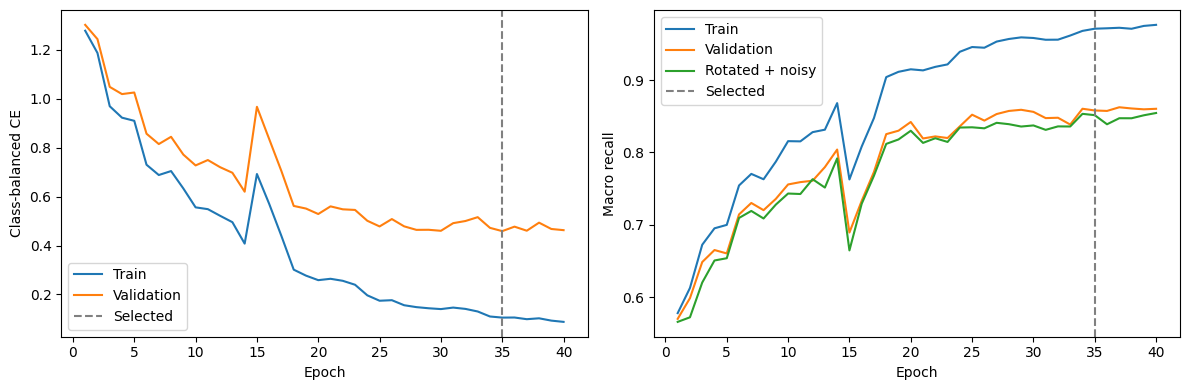

In [ ]:
import matplotlib.pyplot as plt
history = json.loads((run_dir / (chosen["name"] + "_history.json")).read_text())
epochs = [r["epoch"] for r in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, train_key, val_key, label in [
    (axes[0], "train_balanced_loss", "val_balanced_loss", "Class-balanced CE"),
    (axes[1], "train_macro_recall", "val_macro_recall", "Macro recall"),
]:
    ax.plot(epochs, [r[train_key] for r in history], label="Train")
    ax.plot(epochs, [r[val_key] for r in history], label="Validation")
    if val_key == "val_macro_recall":
        ax.plot(epochs, [r["perturbed_macro_recall"] for r in history], label="Rotated + noisy")
    ax.axvline(chosen["epoch"], color="gray", linestyle="--", label="Selected")
    ax.set(xlabel="Epoch", ylabel=label)
    ax.legend()
fig.tight_layout()
fig.savefig(run_dir / "learning_curves.png", dpi=180)
plt.show()


## 8. 최적 회차 복원과 시험 평가
#14의 원본 Kaggle 시험 정확도는 84.86%였다. 같은 분할에서 새 모델의 원본 시험 결과를 비교하고 변형 검증 결과도 함께 확인한다.


In [ ]:
saved = torch.load(chosen["checkpoint"], map_location=device, weights_only=True)
model = ImprovedCNN(len(saved["classes"]), dropout=saved["config"]["dropout"]).to(device)
model.load_state_dict(saved["state"], strict=True)
train_result = measure(model, train_eval_loader)
val_result = measure(model, val_loader)
test_result = measure(model, test_loader)
for name, result in [("학습", train_result), ("검증", val_result), ("시험", test_result)]:
    print(f"{name}: 정확도 {result['acc']:.2%}, CE {result['loss']:.4f}, "
          f"클래스 평균 재현율 {result['macro_recall']:.2%}, "
          f"클래스 평균 CE {result['balanced_loss']:.4f}")
print(f"학습-검증 정확도 차이: {(train_result['acc']-val_result['acc'])*100:.2f}%p")
for name, value in zip(saved["classes"], test_result["recall"]):
    print(name, f"{value:.2%}")
(run_dir / "test_result.json").write_text(json.dumps(
    {"selected": chosen, "train": train_result, "val": val_result, "test": test_result}, indent=2),
    encoding="utf-8")

perturbed = measure(model, perturbed_val_loader)
print("클래스 | 원본 검증 재현율 | 기울기·잡음 검증 재현율")
for name, clean, changed in zip(source.classes, val_result["recall"], perturbed["recall"]):
    print(f"{name:12} {clean:7.2%} {changed:7.2%}")


학습: 정확도 96.21%, CE 0.1296, 클래스 평균 재현율 97.11%, 클래스 평균 CE 0.1055
검증: 정확도 87.23%, CE 0.4076, 클래스 평균 재현율 85.80%, 클래스 평균 CE 0.4589
시험: 정확도 86.67%, CE 0.4296, 클래스 평균 재현율 84.13%, 클래스 평균 CE 0.5091
학습-검증 정확도 차이: 8.98%p
battery 85.11%
biological 84.35%
brown-glass 84.62%
cardboard 93.23%
clothes 92.73%
green-glass 94.57%
metal 79.13%
paper 89.81%
plastic 68.22%
shoes 84.12%
trash 78.85%
white-glass 74.78%
클래스 | 원본 검증 재현율 | 기울기·잡음 검증 재현율
battery       77.30%  74.47%
biological    89.12%  93.20%
brown-glass   95.60%  93.41%
cardboard     88.72%  87.97%
clothes       92.23%  91.10%
green-glass   93.48%  96.74%
metal         80.87%  72.17%
paper         92.99%  90.45%
plastic       70.54%  72.87%
shoes         81.76%  79.39%
trash         82.69%  87.50%
white-glass   84.35%  82.61%


## 8-1. 시험 혼동행렬
이 모델의 실제 예측으로 생성하며 PNG·CSV·개별 예측 기록을 저장합니다.

In [ ]:
import csv
import matplotlib.pyplot as plt

n_classes = len(saved["classes"])
confusion = torch.zeros((n_classes, n_classes), dtype=torch.long)
predictions = []
model.eval()
with torch.no_grad():
    for x, y in test_loader:
        pred = model(x.to(device)).argmax(dim=1).cpu()
        confusion += torch.bincount(
            y * n_classes + pred, minlength=n_classes ** 2
        ).reshape(n_classes, n_classes)
        predictions.extend(pred.tolist())

row_percent = confusion.float() / confusion.sum(dim=1, keepdim=True).clamp_min(1) * 100
fig, axes = plt.subplots(1, 2, figsize=(19, 8))
for ax, matrix, title in zip(axes, [confusion, row_percent],
                              ["Confusion matrix: counts", "Confusion matrix: row %"]):
    plot = ax.imshow(matrix.numpy(), cmap="Blues", vmin=0)
    ax.set_xticks(range(n_classes), saved["classes"], rotation=55, ha="right")
    ax.set_yticks(range(n_classes), saved["classes"])
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(title)
    for i in range(n_classes):
        for j in range(n_classes):
            value = matrix[i, j].item()
            label = str(int(value)) if matrix.dtype == torch.long else f"{value:.1f}"
            color = "white" if value > matrix.max().item() / 2 else "black"
            ax.text(j, i, label, ha="center", va="center", fontsize=7, color=color)
    fig.colorbar(plot, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(run_dir / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

with open(run_dir / "confusion_matrix.csv", "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.writer(f)
    writer.writerow(["true / predicted"] + saved["classes"])
    for name, row in zip(saved["classes"], confusion.tolist()):
        writer.writerow([name] + row)

# test_loader는 shuffle=False이며 test_ids와 동일한 순서입니다.
with open(run_dir / "test_predictions.csv", "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.writer(f)
    writer.writerow(["relative_path", "true_class", "predicted_class"])
    for idx, pred in zip(test_ids, predictions):
        path, label = source.samples[idx]
        writer.writerow([str(Path(path).relative_to(root)),
                         saved["classes"][label], saved["classes"][pred]])
print(f"행렬 기준 정확도: {confusion.diag().sum().item()/confusion.sum().item():.2%}")
print("저장 위치:", run_dir)


## 8-2. 서버 제출 파일 생성·검증
학습 완료 후 실행하면 **개선 모델용 `model.py`와 `weights.pt`**를 만듭니다. 기존 64×64 모델 가중치는 이 모델과 호환되지 않습니다. 아래 ZIP의 두 파일을 반드시 한 쌍으로 제출하세요.

노트북에서 선택된 Dropout이 0.45여도 평가에서는 Dropout이 꺼지므로 기본값 0.3인 제출 클래스와 eval 결과는 같습니다. 이 점도 로짓 비교로 확인합니다. 제출 파일의 Normalize는 개선 모델의 검증 전처리와 일치합니다.


In [ ]:
import importlib.util
from PIL import Image
submission_dir = run_dir / "submission"
submission_dir.mkdir(exist_ok=True)
model_source = '"""김시현 5695460: 개선 CNN 제출용. 기존 64x64 모델 가중치와 호환되지 않음.\n순수 state_dict weights.pt와 함께 제출. logits를 반환하며 사전학습을 사용하지 않음.\n"""\nimport torch\nfrom torch import nn\nfrom torchvision import transforms\n\nCLASSES = [\'battery\', \'biological\', \'brown-glass\', \'cardboard\', \'clothes\', \'green-glass\', \'metal\', \'paper\', \'plastic\', \'shoes\', \'trash\', \'white-glass\']\nIMG_SIZE = 128\n\ndef conv_block(in_channels, out_channels):\n    return nn.Sequential(\n        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),\n        nn.BatchNorm2d(out_channels),\n        nn.ReLU(),\n        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),\n        nn.BatchNorm2d(out_channels),\n        nn.ReLU(),\n        nn.MaxPool2d(2),\n    )\n\n\nclass ImprovedCNN(nn.Module):\n    def __init__(self, n_classes=12, dropout=0.3):\n        super().__init__()\n        self.features = nn.Sequential(\n            conv_block(3, 32),      # 128 -> 64\n            conv_block(32, 64),     # 64 -> 32\n            conv_block(64, 128),    # 32 -> 16\n            conv_block(128, 192),   # 16 -> 8\n        )\n        self.pool = nn.AdaptiveAvgPool2d((4, 4))\n        self.classifier = nn.Sequential(\n            nn.Flatten(),\n            nn.Dropout(dropout),\n            nn.Linear(192 * 4 * 4, 128),\n            nn.ReLU(),\n            nn.Dropout(dropout),\n            nn.Linear(128, n_classes),\n        )\n\n    def forward(self, x):\n        return self.classifier(self.pool(self.features(x)))\n\n\ndef load_model(weights_path, device):\n    model = ImprovedCNN(n_classes=len(CLASSES))\n    state = torch.load(weights_path, map_location=device, weights_only=True)\n    model.load_state_dict(state, strict=True)\n    return model\n\n\ndef get_transform():\n    return transforms.Compose([\n        transforms.Resize((IMG_SIZE, IMG_SIZE)),\n        transforms.ToTensor(),\n        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),\n    ])\n'
(submission_dir / "model.py").write_text(model_source, encoding="utf-8")
best = torch.load(chosen["checkpoint"], map_location="cpu", weights_only=True)
assert best["classes"] == ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
weights_path = submission_dir / "weights.pt"
torch.save(best["state"], weights_path)
spec = importlib.util.spec_from_file_location("improved_submission", submission_dir / "model.py")
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
net = module.load_model(str(weights_path), "cpu").to("cpu").eval()
reference = ImprovedCNN(12, dropout=best["config"]["dropout"])
reference.load_state_dict(best["state"], strict=True)
reference.eval()
picture = Image.open(source.samples[test_ids[0]][0]).convert("RGB")
x = module.get_transform()(picture)
assert x.shape == (3, 128, 128)
torch.testing.assert_close(x, plain_tf(picture), rtol=0, atol=0)
with torch.no_grad():
    y = net(x.unsqueeze(0))
    expected = reference(x.unsqueeze(0))
assert y.shape == (1, 12) and torch.isfinite(y).all()
torch.testing.assert_close(y, expected, rtol=0, atol=0)
print("제출 계약·전처리·로짓 일치 확인:", y.shape)
print("가중치 크기:", round(weights_path.stat().st_size / 1024**2, 2), "MiB")


In [ ]:
from zipfile import ZipFile
from google.colab import files
submission_zip = run_dir / "5695460_noise_angle_submission.zip"
with ZipFile(submission_zip, "w") as archive:
    archive.write(submission_dir / "model.py", arcname="model.py")
    archive.write(submission_dir / "weights.pt", arcname="weights.pt")
files.download(str(submission_zip))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. 전체 기록 다운로드
학습 기록·비교표·혼동행렬·분할·제출 파일을 함께 보관합니다.

In [ ]:
import shutil
result_zip = shutil.make_archive(str(run_dir), "zip", root_dir=run_dir)
files.download(result_zip)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 출처 및 AI 사용 기록
- 데이터 https://www.kaggle.com/datasets/mostafaabla/garbage-classification
- #14 학습 코드의 1~2절 다운로드·분할, 3절 전처리, 4절 모델, 5~6절 평가·학습 및 8-2절 제출 형식을 참고했다.
- 3절에서 추가한 반사 패딩·아핀 변환·가우시안 노이즈는 이번 실험의 응용이다.
- 프롬프트: “결합하지 말고 다른 개선 방법으로 개선해줘 예를들어 이미지 파일에 노이즈나 각도를 바꾸는 변형을 주든 아니면 너가 생각하는 다른 개선방법을 적용해서 개선 코드짜줘 단 파이토치 CNN 을 써야해”
